# Import Required Libraries
Import the necessary libraries, including cProfile and pstats.

In [1]:
# Import the necessary libraries for profiling and visualizing the results
import cProfile
import pstats

In [2]:
from anemone.experiment import *
from anemone.forwards import *
import torch

# Define the Function to Profile
Define the function or code block that you want to profile.

In [3]:
# Define the function to profile

tx = Loop.square(40)
rx = Receiver()
time = torch.logspace(-5, -3, 31)

rho = torch.ones(3)*40.
rho_change = torch.linspace(-30, 260, 10)
rho = rho[:, None] + rho_change[None, :]
rho[0, :] = 40.
rho[2, :] = 40.

thick = torch.ones_like(rho)[:-1, :]*30

gpu = torch.device("cuda:0")
rho = rho.to(gpu)
thick = thick.to(gpu)
time = time.to(gpu)

fwr = ForwardLaplace3(tx, rx, time, waveform=Waveform.example())
dbdt = fwr(rho, thick)

/home/matt/repositories/anemone/src/anemone/forwards/forwards.py:15: UserWarning: This forward is pretty slow.
  warnings.warn("This forward is pretty slow.")
/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [4]:
%%timeit
dbdt = fwr(torch.ones(3, device=gpu)*40., torch.ones(2, device=gpu)*30.)

17.4 ms ± 111 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [5]:
fwr = ForwardLaplace6(tx, rx, time, waveform=Waveform.example())
dbdt = fwr(torch.ones(3, device=gpu)*40., torch.ones(2, device=gpu)*30.)

In [6]:
%%timeit
dbdt = fwr(torch.ones(3, device=gpu)*40., torch.ones(2, device=gpu)*30.)

1.99 ms ± 40.8 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [7]:
rho = torch.ones(3)*40.
rho_change = torch.linspace(-30, 260, 100)
rho = rho[:, None] + rho_change[None, :]
rho[0, :] = 40.
rho[2, :] = 40.

thick = torch.ones_like(rho)[:-1, :]*30

gpu = torch.device("cuda:0")
rho = rho.to(gpu)
thick = thick.to(gpu)
time = time.to(gpu)

In [8]:
%%timeit
dbdt = fwr(rho, thick)

115 ms ± 318 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


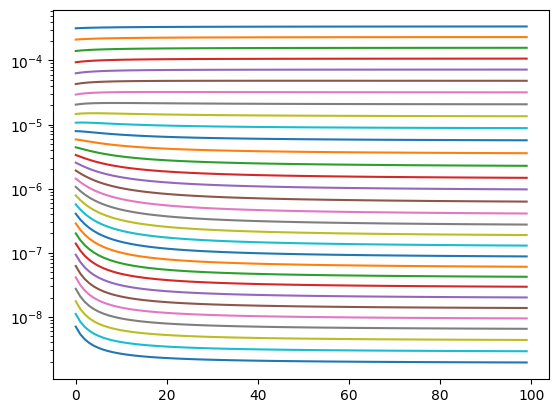

In [9]:
import matplotlib.pyplot as plt
import numpy as np
dbdt = fwr(rho, thick)
plt.figure()
plt.semilogy(dbdt.cpu());

In [11]:
%%timeit

dbdt = fwr(rho, thick)

423 ms ± 27.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


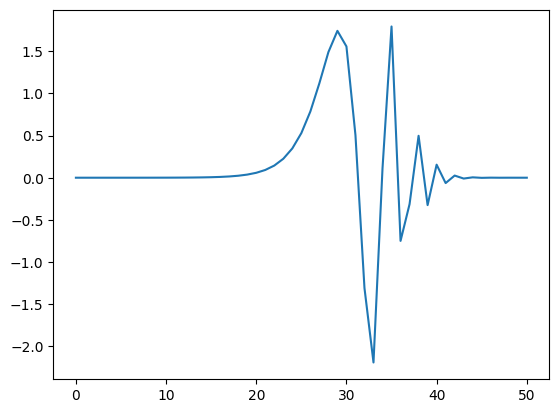

In [9]:
plt.figure()
plt.plot(fwr.geomz)

In [ ]:
from time import time as timer
bt = timer()
dbdt = fwr(rho, thick)
print(f'time {timer() - bt:.3f} s')

time 2.123 s


: 

In [ ]:
def example_function():
    dbdt = fwr(rho, thick)

: 

# Use cProfile to Profile the Function
Use the cProfile.run() function to profile the defined function or code block.

In [ ]:
# Use cProfile to Profile the Function
cProfile.run('example_function()', 'profile_output')

# Load the profiling results
profile_stats = pstats.Stats('profile_output')

# Sort the statistics by cumulative time and print the top 10 functions
profile_stats.sort_stats('cumulative').print_stats(25)

Fri May  9 20:06:24 2025    profile_output

         914 function calls (899 primitive calls) in 2.183 seconds

   Ordered by: cumulative time
   List reduced from 211 to 25 due to restriction <25>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      2/1    0.000    0.000    2.182    2.182 {built-in method builtins.exec}
      2/1    0.000    0.000    2.182    2.182 <string>:1(<module>)
      2/1    0.000    0.000    2.182    2.182 /tmp/ipykernel_92961/3089854814.py:1(example_function)
        1    0.000    0.000    2.178    2.178 /home/matt/repositories/anemone/src/anemone/forwards/forwards.py:695(__call__)
        1    0.000    0.000    2.178    2.178 /home/matt/repositories/anemone/src/anemone/forwards/forwards.py:624(forward)
        1    0.000    0.000    2.178    2.178 /home/matt/repositories/anemone/src/anemone/transforms/transforms.py:614(range)
        1    0.001    0.001    2.178    2.178 /home/matt/repositories/anemone/src/anemone/transforms/transfo

: 

# Visualize Profiling Results with pstats
Use the pstats module to load and visualize the profiling results.

In [ ]:
# Visualize Profiling Results with pstats

# Strip directories to shorten the output
profile_stats.strip_dirs()

# Sort the statistics by time spent within each function and print the top 10 functions
profile_stats.sort_stats('time').print_stats()

# Print the callers of the top 10 functions
profile_stats.print_callers()

Fri May  9 20:06:24 2025    profile_output

         914 function calls (899 primitive calls) in 2.183 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.865    0.865    1.473    1.473 physics.py:478(calc_prop_matrix)
        1    0.286    0.286    1.984    1.984 physics.py:569(rte_matrix)
        3    0.208    0.069    0.208    0.069 {built-in method torch.zeros}
       10    0.150    0.015    0.150    0.015 {built-in method torch.einsum}
        1    0.143    0.143    0.143    0.143 {built-in method torch.exp}
        1    0.138    0.138    2.122    2.122 forwards.py:627(s_integrand)
        2    0.095    0.047    0.095    0.047 {built-in method torch.sqrt}
        1    0.064    0.064    0.064    0.064 {built-in method torch.roll}
        3    0.061    0.020    0.118    0.039 _tensor.py:1030(__rdiv__)
        3    0.057    0.019    0.057    0.019 {method 'reciprocal' of 'torch._C.TensorBase' objects}
        1

: 

: 

: 